# 3 - Análise descritiva por gênero

Esta análise usa a **amostra principal**, que contém apenas casos completos de renda, DTI e LTV, conforme o protocolo (seção 4). A versão com imputação (`amostra_alternativa`) fica reservada para a análise de robustez.

O objetivo é mapear diferenças brutas entre homens e mulheres, verificar a qualidade dos dados e comparar perfis de risco observáveis.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 180

## 1. Leitura e visão geral

In [2]:
data = pd.read_parquet("../data/amostra_principal.parquet")

data["genero"] = data["mulher"].map({0: "Homem", 1: "Mulher"})
data["resultado"] = data["negado"].map({0: "Aprovado", 1: "Negado"})

print(f"Linhas: {len(data):,}")
print(f"Colunas: {data.shape[1]}")
print(f"Instituições distintas: {data['lei'].nunique():,}")
print(f"Estados distintos: {data['state_code'].nunique(dropna=True)}")

data.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/amostra_principal.parquet'

In [ ]:
qualidade = pd.DataFrame({
    "faltantes": data.isna().sum(),
    "percentual": data.isna().mean() * 100,
    "tipo": data.dtypes.astype(str),
}).sort_values("faltantes", ascending=False)

qualidade

,faltantes,percentual,tipo
total_loan_costs,202357,13.0785,float64
rate_spread,181012,11.6990,float64
interest_rate,172320,11.1372,float64
state_code,7195,0.4650,str
property_value,4806,0.3106,float64
loan_term,2719,0.1757,float64
applicant_age,130,0.0084,str
combined_loan_to_value_ratio,0,0.0000,float64
loan_amount,0,0.0000,float64
lei,0,0.0000,str


A amostra principal não tem valores imputados, então não há indicadores de faltante. Os faltantes que restam (por exemplo, `interest_rate`, `rate_spread` e `total_loan_costs`) são naturais a determinados resultados, como custos e taxas em pedidos negados.

In [ ]:
geral = pd.DataFrame({
    "valor": [len(data), data["lei"].nunique(), data["negado"].mean(), data["mulher"].mean()],
}, index=["linhas", "instituições", "taxa de negação", "proporção de mulheres"])

geral

,valor
linhas,"1,547,246.0000"
instituições,"2,438.0000"
taxa de negação,0.1113
proporção de mulheres,0.3897


## 2. Desfecho por gênero

A taxa bruta de negação é comparada entre homens e mulheres com um intervalo de confiança de 95% baseado em Wilson.

In [ ]:
def wilson_interval(successes, n, z=1.96):
    p = successes / n
    denominator = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denominator
    margin = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / denominator
    return center - margin, center + margin

genero_resumo = data.groupby("genero").agg(
    solicitacoes=("negado", "size"),
    negacoes=("negado", "sum"),
).reset_index()
genero_resumo["taxa_negacao"] = genero_resumo["negacoes"] / genero_resumo["solicitacoes"]
intervalos = genero_resumo.apply(
    lambda r: wilson_interval(r["negacoes"], r["solicitacoes"]), axis=1
)
genero_resumo["ic95_inferior"] = [x[0] for x in intervalos]
genero_resumo["ic95_superior"] = [x[1] for x in intervalos]

genero_resumo

,genero,solicitacoes,negacoes,taxa_negacao,ic95_inferior,ic95_superior
0,Homem,944301,99358,0.1052,0.1046,0.1058
1,Mulher,602945,72907,0.1209,0.1201,0.1217


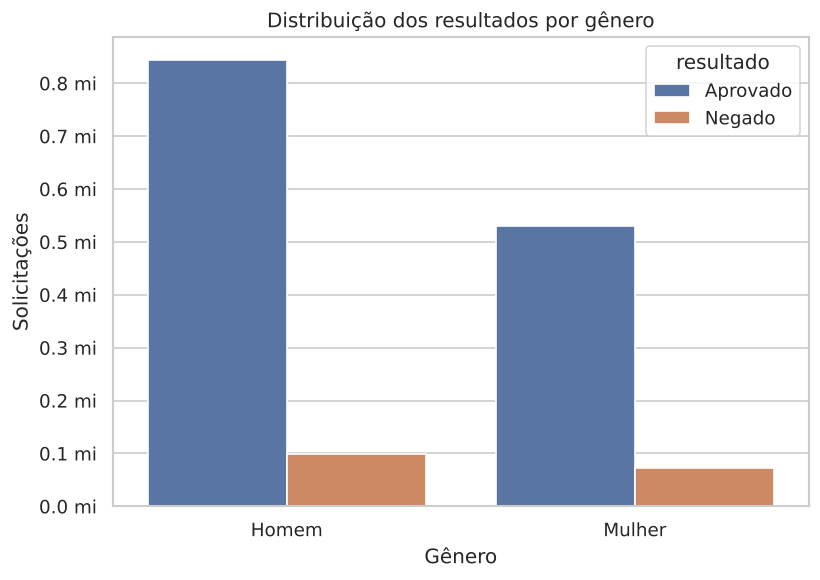

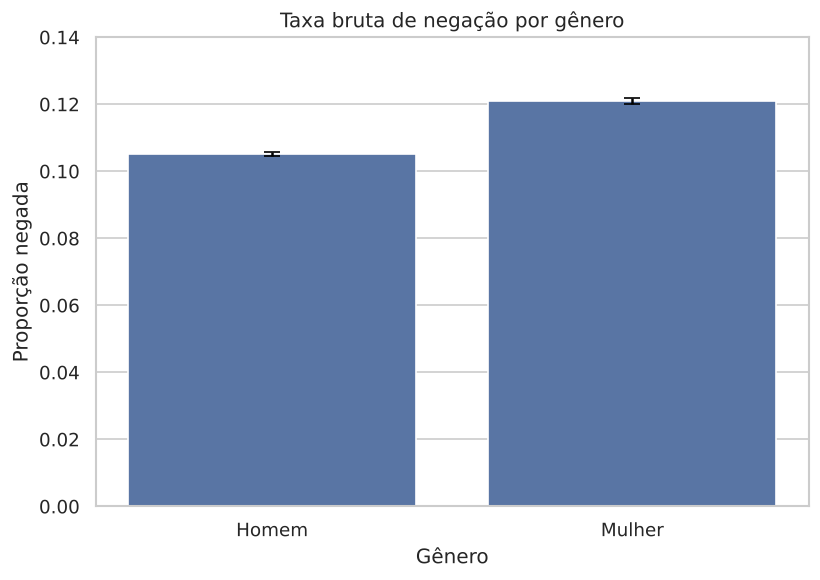

Diferença bruta (mulheres - homens): 1.57 pontos percentuais


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
plot_data = data.groupby(["genero", "resultado"]).size().rename("contagem").reset_index()
sns.barplot(data=plot_data, x="genero", y="contagem", hue="resultado", ax=ax)
ax.set_title("Distribuição dos resultados por gênero")
ax.set_xlabel("Gênero")
ax.set_ylabel("Solicitações")
ax.ticklabel_format(axis="y", style="plain")
ax.get_yaxis().set_major_formatter(lambda x, pos: f"{x/1e6:.1f} mi")
plt.tight_layout()
plt.savefig("../figuras/negacao_por_genero_contagem.png")
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(data=genero_resumo, x="genero", y="taxa_negacao", ax=ax)
ax.errorbar(
    x=np.arange(len(genero_resumo)),
    y=genero_resumo["taxa_negacao"],
    yerr=[
        genero_resumo["taxa_negacao"] - genero_resumo["ic95_inferior"],
        genero_resumo["ic95_superior"] - genero_resumo["taxa_negacao"],
    ],
    fmt="none", ecolor="black", capsize=5
)
ax.set_title("Taxa bruta de negação por gênero")
ax.set_xlabel("Gênero")
ax.set_ylabel("Proporção negada")
ax.set_ylim(0, max(genero_resumo["ic95_superior"])*1.15)
plt.tight_layout()
plt.savefig("../figuras/taxa_negacao_por_genero.png")
plt.show()

diferenca = genero_resumo.loc[genero_resumo["genero"] == "Mulher", "taxa_negacao"].iloc[0] - genero_resumo.loc[genero_resumo["genero"] == "Homem", "taxa_negacao"].iloc[0]
print(f"Diferença bruta (mulheres - homens): {diferenca*100:.2f} pontos percentuais")

## 3. Variáveis numéricas

Médias podem ser distorcidas por valores extremos. Por isso, a comparação principal usa mediana e intervalos interquartis. Os histogramas usam uma amostra aleatória e limitam o eixo ao percentil 99.

In [ ]:
numericas = [
    "income", "loan_amount", "property_value",
    "combined_loan_to_value_ratio", "tract_minority_population_percent",
    "tract_to_msa_income_percentage"
]

resumo_numerico = data.groupby("genero")[numericas].agg(["count", "median", "std", "min", "max"])
resumo_numerico

income                                              loan_amount  \
         count  median        std          min          max       count   
genero                                                                    
Homem   944301 95.0000 1,110.4430 -52,661.0000 535,182.0000      944301   
Mulher  602945 81.0000   483.3895  -8,148.0000 155,987.0000      602945   

                                                            property_value  \
             median          std        min             max          count   
genero                                                                       
Homem  305,000.0000 335,722.7419 5,000.0000 63,105,000.0000         941676   
Mulher 265,000.0000 219,588.7156 5,000.0000 15,405,000.0000         600764   

                                                              \
             median          std        min              max   
genero                                                         
Homem  345,000.0000 733,930.7936 5,000.0000 510,005,000.0000   
Mulher 315,000.0000 703,391.3147 5,000.0000 365,005,000.0000   

       combined_loan_to_value_ratio                             \
                              count  median         std    min   
genero                                                           
Homem                        944301 95.0000 43,459.5834 0.0010   
Mulher                       602945 93.5990 28,041.9233 0.0070   

                       tract_minority_population_percent                  \
                   max                             count  median     std   
genero                                                                     
Homem  29,500,000.0000                            944301 30.1800 25.0650   
Mulher 15,000,000.0000                            602945 32.6600 26.2181   

                       tract_to_msa_income_percentage                          \
          min      max                          count   median     std    min   
genero                                                                          
Homem  0.0000 100.0000                         944301 104.0000 40.7665 0.0000   
Mulher 0.0000 100.0000                         602945 101.0000 39.9631 0.0000   

                 
            max  
genero           
Homem  516.0000  
Mulher 516.0000

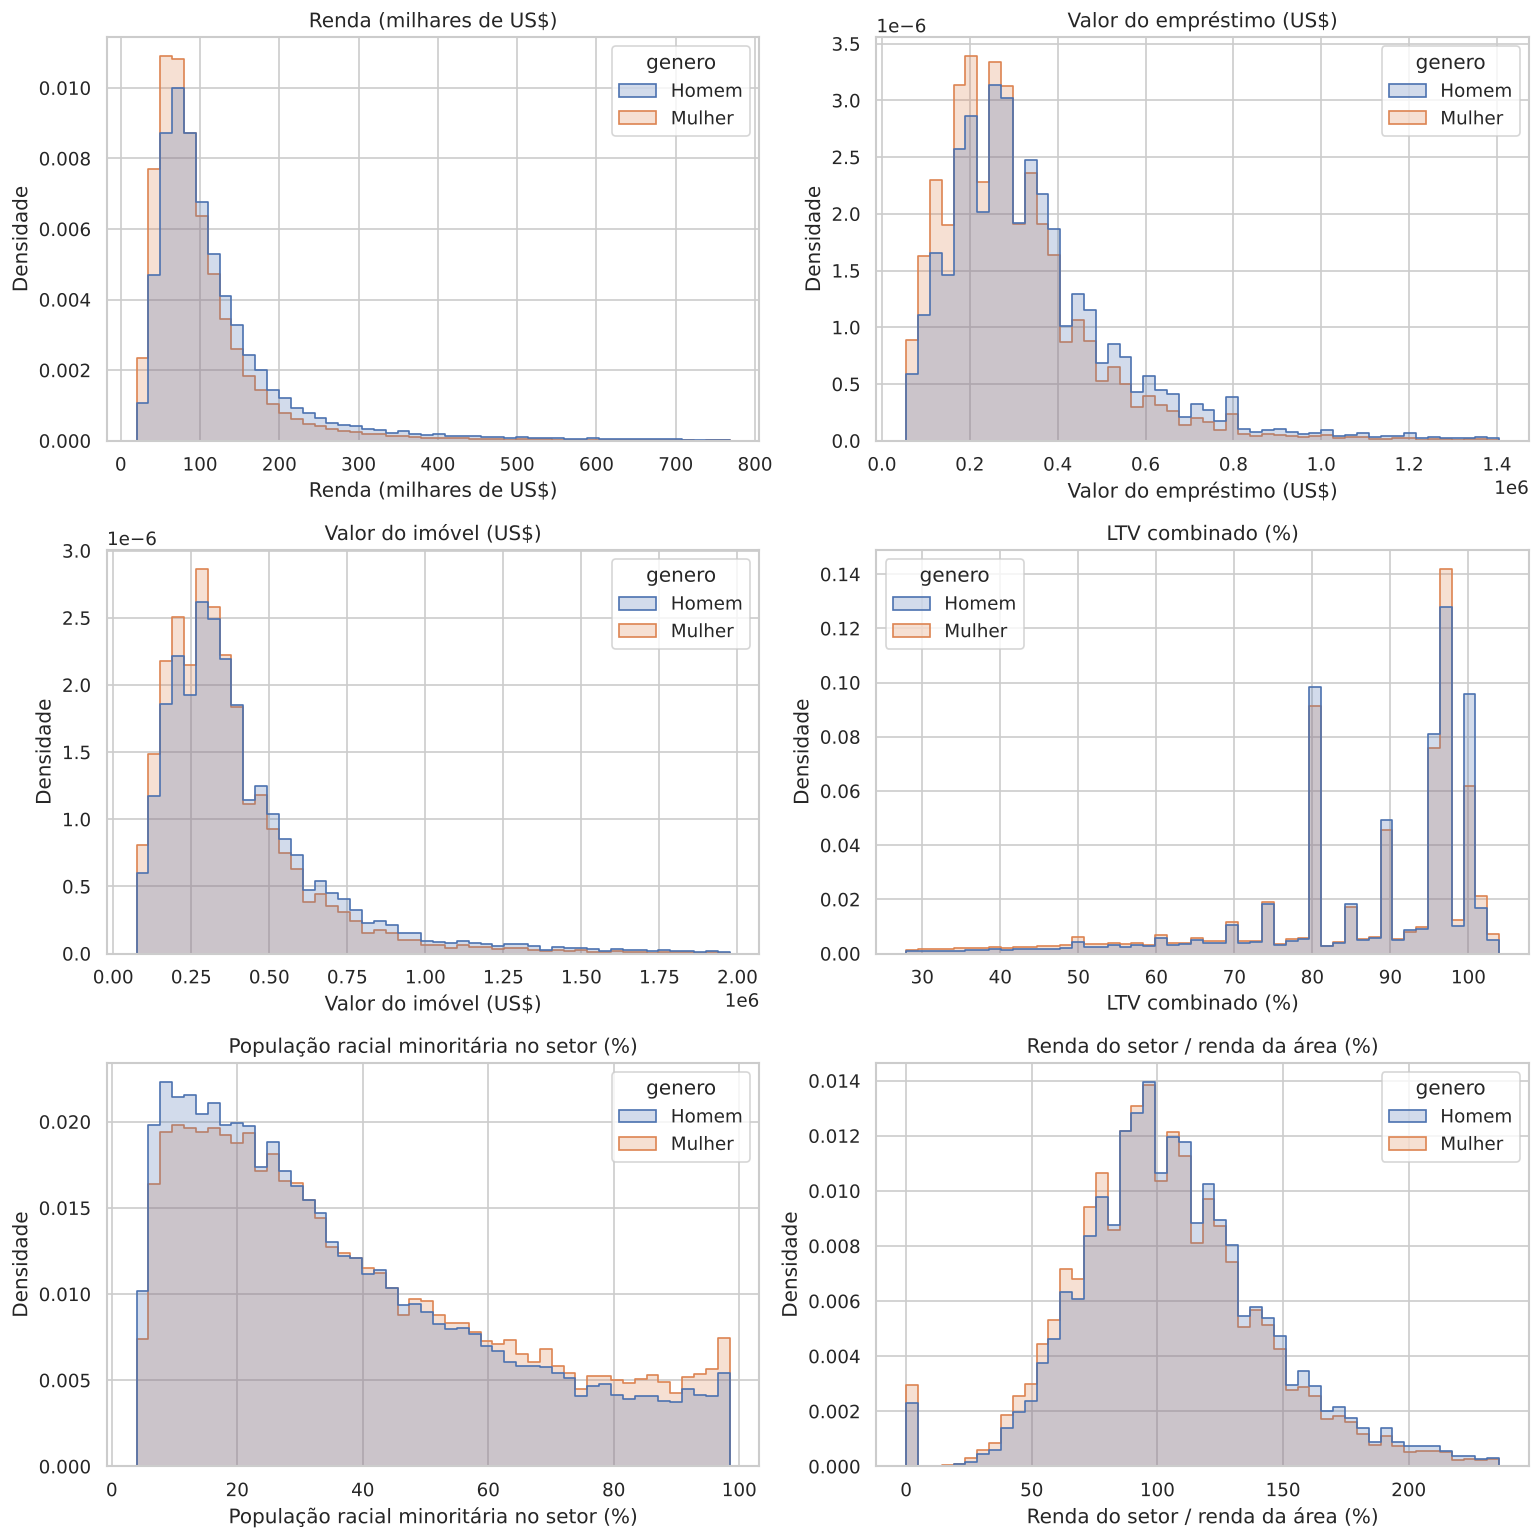

In [ ]:
labels = {
    "income": "Renda (milhares de US$)",
    "loan_amount": "Valor do empréstimo (US$)",
    "property_value": "Valor do imóvel (US$)",
    "combined_loan_to_value_ratio": "LTV combinado (%)",
    "tract_minority_population_percent": "População racial minoritária no setor (%)",
    "tract_to_msa_income_percentage": "Renda do setor / renda da área (%)"
}

amostra = data.sample(n=min(300_000, len(data)), random_state=42)

fig, axes = plt.subplots(3, 2, figsize=(13, 13))
for ax, coluna in zip(axes.ravel(), numericas):
    limite = amostra[coluna].quantile(0.99)
    inf, sup = amostra[coluna].quantile([0.01, 0.99])
    sns.histplot(
        data=amostra[amostra[coluna].notna() & (amostra[coluna] <= limite)],
        x=coluna, hue="genero", stat="density",
        common_norm=False, element="step", ax=ax, bins=50, binrange=(inf, sup)
    )
    ax.set_title(labels[coluna])
    ax.set_xlabel(labels[coluna])
    ax.set_ylabel("Densidade")

plt.tight_layout()
plt.savefig("../figuras/distribuicoes_numericas_por_genero.png")
plt.show()

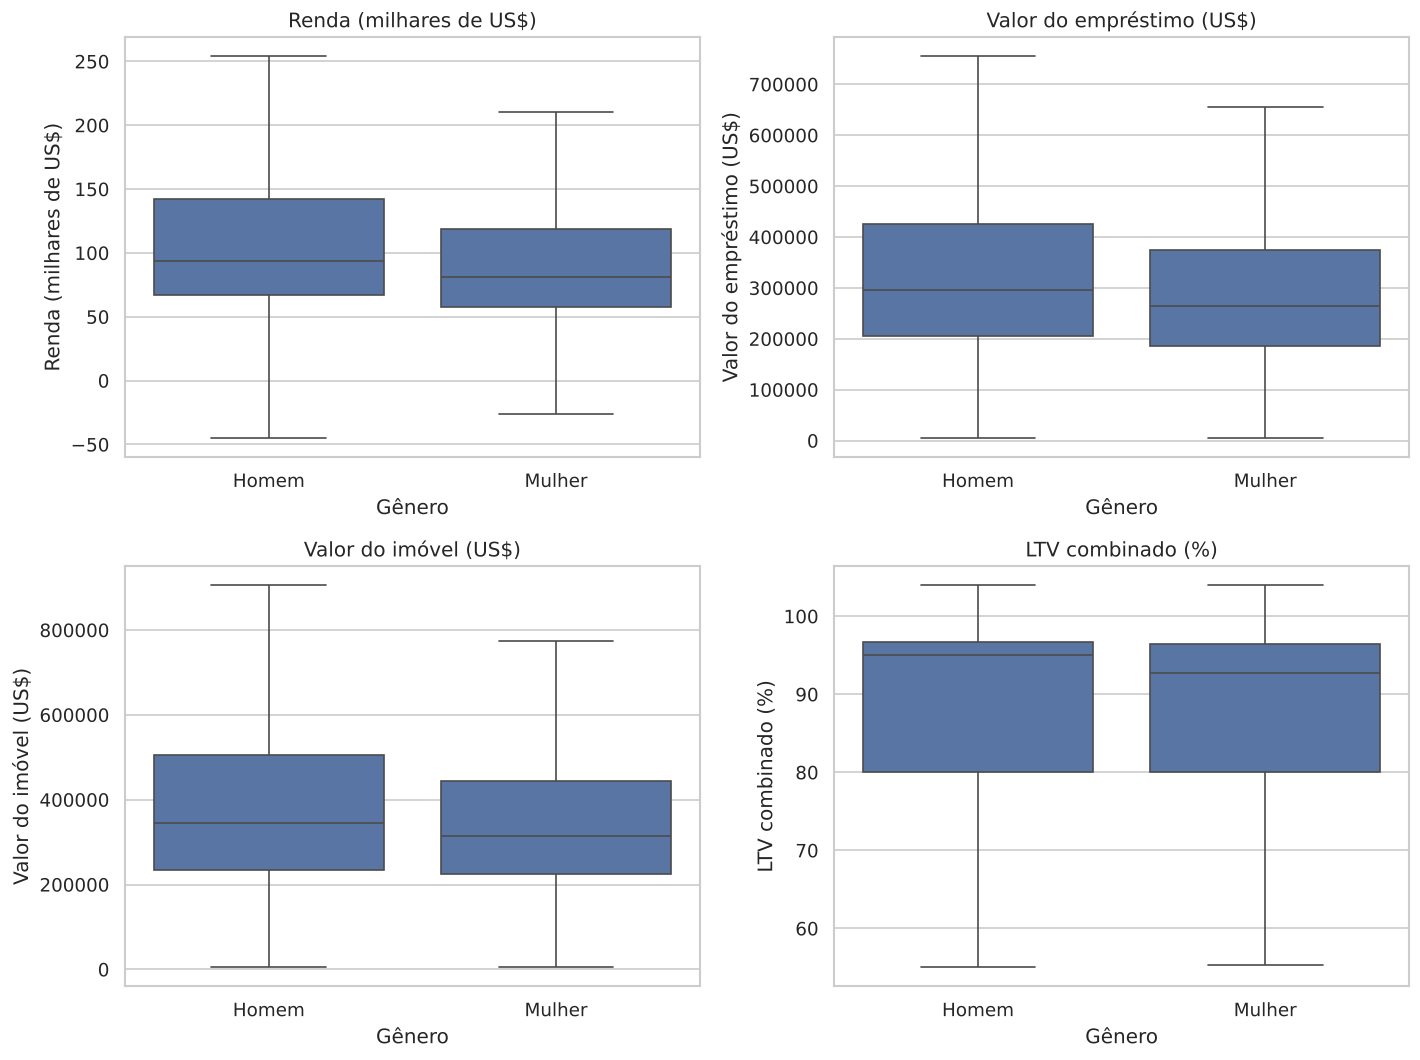

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
colunas_box = ["income", "loan_amount", "property_value", "combined_loan_to_value_ratio"]

for ax, coluna in zip(axes.ravel(), colunas_box):
    limite = amostra[coluna].quantile(0.99)
    plot_data = amostra[amostra[coluna].notna() & (amostra[coluna] <= limite)]
    sns.boxplot(data=plot_data, x="genero", y=coluna, ax=ax, showfliers=False)
    ax.set_title(labels[coluna])
    ax.set_xlabel("Gênero")
    ax.set_ylabel(labels[coluna])

plt.tight_layout()
plt.savefig("../figuras/boxplots_numericos_por_genero.png")
plt.show()

## 4. Variáveis categóricas

As tabelas abaixo apresentam a composição percentual dentro de cada gênero, permitindo comparar perfis mesmo com diferentes tamanhos de grupo.

In [ ]:
categoricas = ["dti", "applicant_age", "loan_type", "derived_race", "derived_ethnicity"]

for coluna in categoricas:
    tabela = pd.crosstab(data[coluna], data["genero"], normalize="columns") * 100
    print(f"\nDistribuição percentual — {coluna}")
    display(tabela.sort_values("Homem", ascending=False).round(2))


Distribuição percentual — dti


genero,Homem,Mulher
dti,,
36%-<50%,54.9500,58.6800
30%-<36%,14.4800,12.9900
20%-<30%,12.5200,10.3000
50%-60%,11.1100,11.8900
<20%,4.0600,2.7600
>60%,2.8800,3.3900



Distribuição percentual — applicant_age


genero,Homem,Mulher
applicant_age,,
25-34,33.9400,27.6400
35-44,26.8900,26.1400
45-54,15.7300,18.6200
55-64,9.6200,13.2000
<25,8.8500,5.3300
65-74,3.8200,6.9400
>74,1.1500,2.1400



Distribuição percentual — loan_type


genero,Homem,Mulher
loan_type,,
1,63.5800,66.9100
2,22.2900,27.2300
3,12.6900,4.4700
4,1.4400,1.3900



Distribuição percentual — derived_race


genero,Homem,Mulher
derived_race,,
White,70.8500,66.1300
Race Not Available,10.1500,9.6700
Black or African American,8.8300,15.9500
Asian,8.3900,6.5800
American Indian or Alaska Native,1.1500,1.0300
2 or more minority races,0.3600,0.4200
Native Hawaiian or Other Pacific Islander,0.2500,0.2100
Free Form Text Only,0.0200,0.0100
Joint,0.0000,0.0000



Distribuição percentual — derived_ethnicity


genero,Homem,Mulher
derived_ethnicity,,
Not Hispanic or Latino,72.7800,75.6700
Hispanic or Latino,18.1400,15.9100
Ethnicity Not Available,8.6700,7.9700
Joint,0.3900,0.4200
Free Form Text Only,0.0300,0.0200


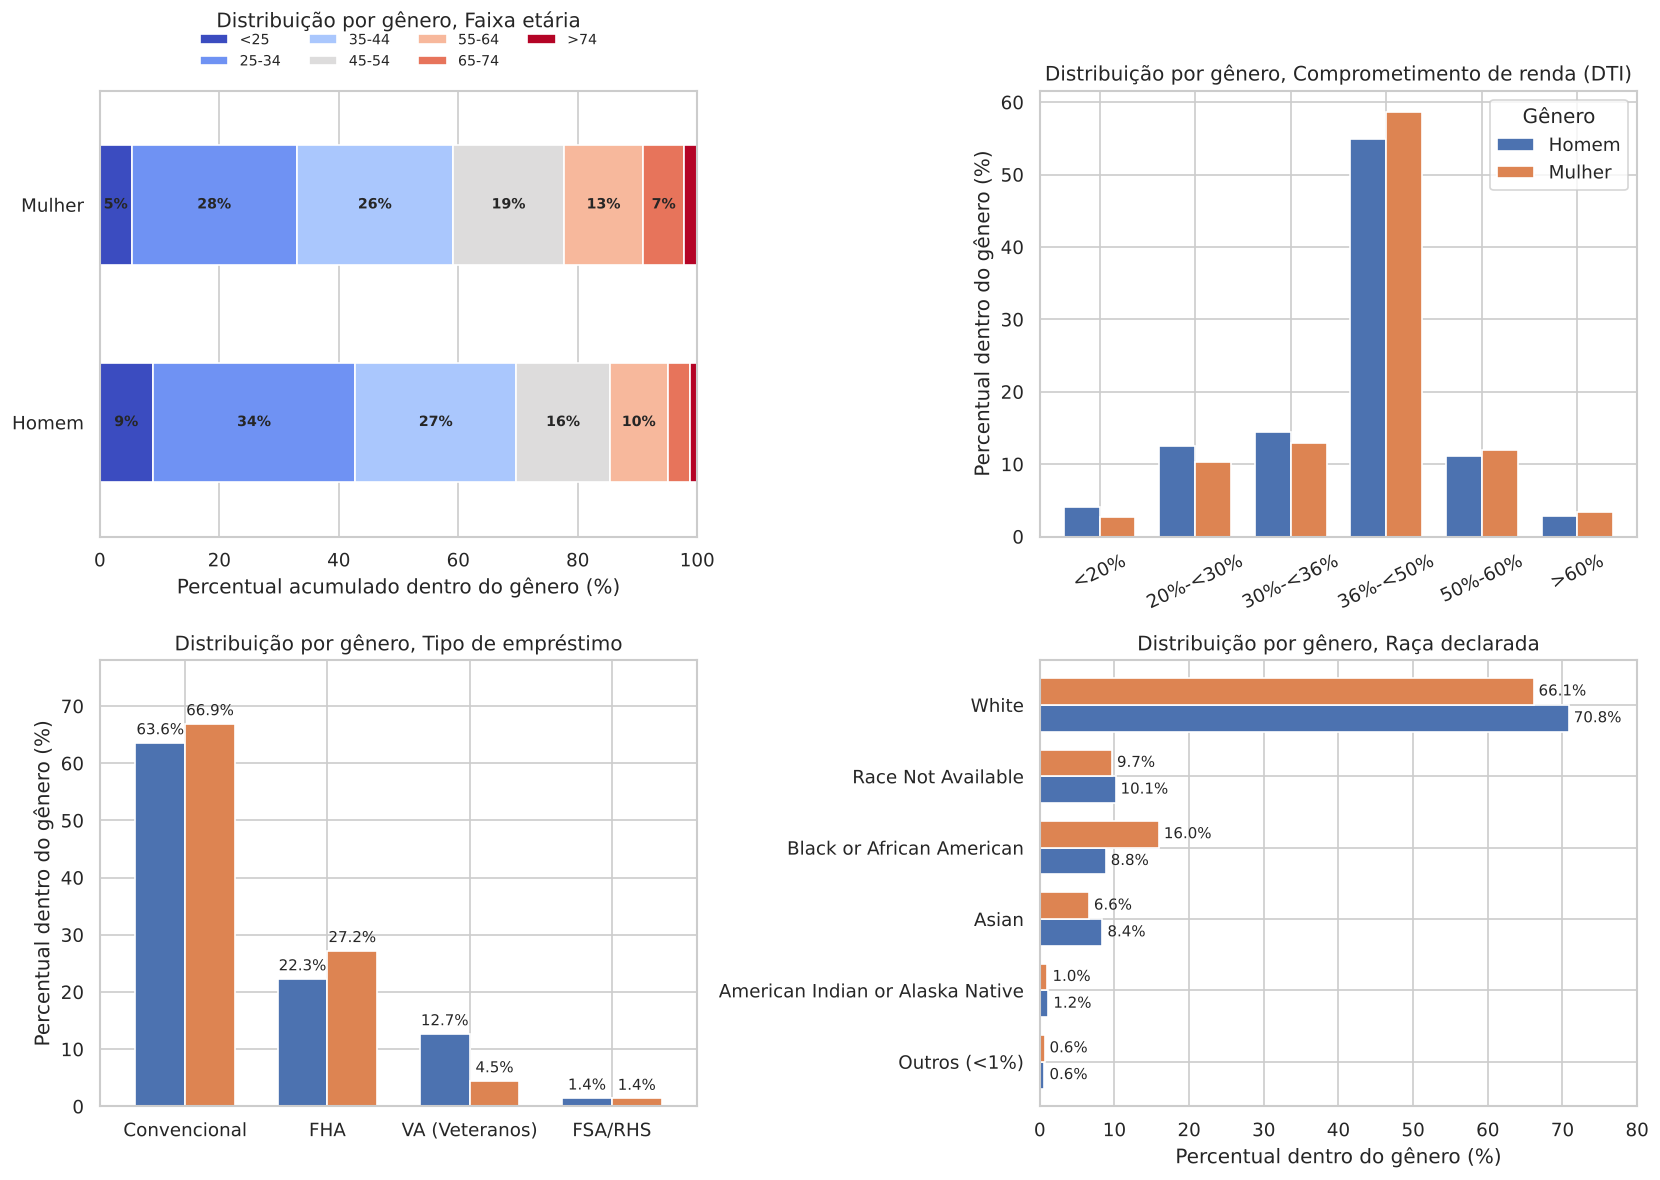

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Faixa etária
ordem_idade = ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"]
tab_idade = (pd.crosstab(data["applicant_age"], data["genero"], normalize="columns") * 100).reindex(ordem_idade)

tab_idade.T.plot(
    kind="barh",
    stacked=True,
    width=0.55,
    colormap="coolwarm",
    edgecolor="white",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Distribuição por gênero, Faixa etária", pad=38)
axes[0, 0].set_xlabel("Percentual acumulado dentro do gênero (%)")
axes[0, 0].set_ylabel("")
axes[0, 0].set_xlim(0, 100)
axes[0, 0].legend(
    bbox_to_anchor=(0.5, 1.02),
    loc="lower center",
    ncol=4,
    frameon=False,
    fontsize=8.5
)

for container in axes[0, 0].containers:
    rotulos = [f"{v:.0f}%" if v >= 5 else "" for v in container.datavalues]
    axes[0, 0].bar_label(container, labels=rotulos, label_type="center", fontsize=8.5, fontweight="bold")

# 2. DTI
ordem_dti = ["<20%", "20%-<30%", "30%-<36%", "36%-<50%", "50%-60%", ">60%"]
tab_dti = (pd.crosstab(data["dti"], data["genero"], normalize="columns") * 100).reindex(ordem_dti)

tab_dti.plot(kind="bar", width=0.75, ax=axes[0, 1])
axes[0, 1].set_title("Distribuição por gênero, Comprometimento de renda (DTI)")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Percentual dentro do gênero (%)")
axes[0, 1].tick_params(axis="x", rotation=25)
axes[0, 1].legend(title="Gênero")

# 3. Tipo de empréstimo
mapa_loan = {
    1: "Convencional", "1": "Convencional",
    2: "FHA", "2": "FHA",
    3: "VA (Veteranos)", "3": "VA (Veteranos)",
    4: "FSA/RHS", "4": "FSA/RHS"
}
tab_loan = (pd.crosstab(data["loan_type"], data["genero"], normalize="columns") * 100).rename(index=mapa_loan)

tab_loan.plot(kind="bar", width=0.7, ax=axes[1, 0], legend=False)
axes[1, 0].set_title("Distribuição por gênero, Tipo de empréstimo")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Percentual dentro do gênero (%)")
axes[1, 0].set_ylim(0, 78)
axes[1, 0].tick_params(axis="x", rotation=0)
axes[1, 0].bar_label(axes[1, 0].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
axes[1, 0].bar_label(axes[1, 0].containers[1], fmt="%.1f%%", padding=3, fontsize=9)

# 4. Raça declarada
tab_race = pd.crosstab(data["derived_race"], data["genero"], normalize="columns") * 100
raras = tab_race.max(axis=1) < 1.0
tab_race_limpa = pd.concat([
    pd.DataFrame(tab_race[raras].sum(), columns=["Outros (<1%)"]).T,
    tab_race[~raras].sort_values(by="Homem", ascending=True)
])

tab_race_limpa.plot(kind="barh", width=0.75, ax=axes[1, 1], legend=False)
axes[1, 1].set_title("Distribuição por gênero, Raça declarada")
axes[1, 1].set_xlabel("Percentual dentro do gênero (%)")
axes[1, 1].set_ylabel("")
axes[1, 1].set_xlim(0, 80)
axes[1, 1].bar_label(axes[1, 1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
axes[1, 1].bar_label(axes[1, 1].containers[1], fmt="%.1f%%", padding=3, fontsize=9)

plt.tight_layout()
plt.savefig("../figuras/categoricas_por_genero.png", dpi=300)
plt.show()

## 5. Taxa de negação dentro de perfis observáveis

In [ ]:
estratos = data.copy()
estratos["faixa_renda"] = pd.qcut(estratos["income"], q=5, duplicates="drop")
estratos["faixa_ltv"] = pd.qcut(estratos["combined_loan_to_value_ratio"], q=5, duplicates="drop")

for coluna, titulo in [("dti", "DTI"), ("applicant_age", "Idade"), ("loan_type", "Tipo de empréstimo")]:
    tabela = estratos.groupby([coluna, "genero"], observed=True)["negado"].agg(["size", "mean"]).reset_index()
    tabela["taxa_%"] = tabela["mean"] * 100
    tabela = tabela.pivot(index=coluna, columns="genero", values="taxa_%")
    tabela["diferença_p.p."] = tabela.get("Mulher") - tabela.get("Homem")
    print(f"\nTaxa de negação por {titulo}")
    display(tabela.round(2))

for coluna, titulo in [("faixa_renda", "Renda"), ("faixa_ltv", "LTV")]:
    tabela = estratos.groupby([coluna, "genero"], observed=True)["negado"].agg(["size", "mean"]).reset_index()
    tabela["taxa_%"] = tabela["mean"] * 100
    tabela = tabela.pivot(index=coluna, columns="genero", values="taxa_%")
    tabela["diferença_p.p."] = tabela.get("Mulher") - tabela.get("Homem")
    print(f"\nTaxa de negação por {titulo}")
    display(tabela.round(2))


Taxa de negação por DTI


genero,Homem,Mulher,diferença_p.p.
dti,,,
<20%,17.0900,19.1900,2.1000
20%-<30%,7.2900,7.5200,0.2400
30%-<36%,6.4900,7.0300,0.5400
36%-<50%,6.6100,7.2000,0.5800
50%-60%,17.8500,21.3100,3.4600
>60%,81.8300,91.8800,10.0600



Taxa de negação por Idade


genero,Homem,Mulher,diferença_p.p.
applicant_age,,,
25-34,9.0600,10.8700,1.8200
35-44,10.5600,12.5600,2.0000
45-54,11.8800,12.9800,1.1000
55-64,12.2400,12.7200,0.4900
65-74,12.4000,10.8200,-1.5800
<25,10.7000,13.5100,2.8100
>74,11.9500,10.7400,-1.2100



Taxa de negação por Tipo de empréstimo


genero,Homem,Mulher,diferença_p.p.
loan_type,,,
1,9.9800,11.1300,1.1500
2,12.8100,14.6600,1.8500
3,9.0500,10.3700,1.3200
4,11.8800,13.5600,1.6900



Taxa de negação por Renda


genero,Homem,Mulher,diferença_p.p.
faixa_renda,,,
"(-52661.001, 59.0]",20.3700,21.7600,1.3900
"(59.0, 78.0]",10.6000,10.5800,-0.0300
"(78.0, 103.0]",8.6500,8.5700,-0.0800
"(103.0, 150.0]",7.6700,7.7000,0.0400
"(150.0, 535182.0]",7.2600,7.2200,-0.0400



Taxa de negação por LTV


genero,Homem,Mulher,diferença_p.p.
faixa_ltv,,,
"(0.0, 79.9]",7.9100,7.8800,-0.0300
"(79.9, 89.763]",8.1300,8.5600,0.4300
"(89.763, 95.0]",11.1400,13.4700,2.3300
"(95.0, 97.0]",11.7800,14.0200,2.2400
"(97.0, 29500000.0]",13.4600,17.6100,4.1600


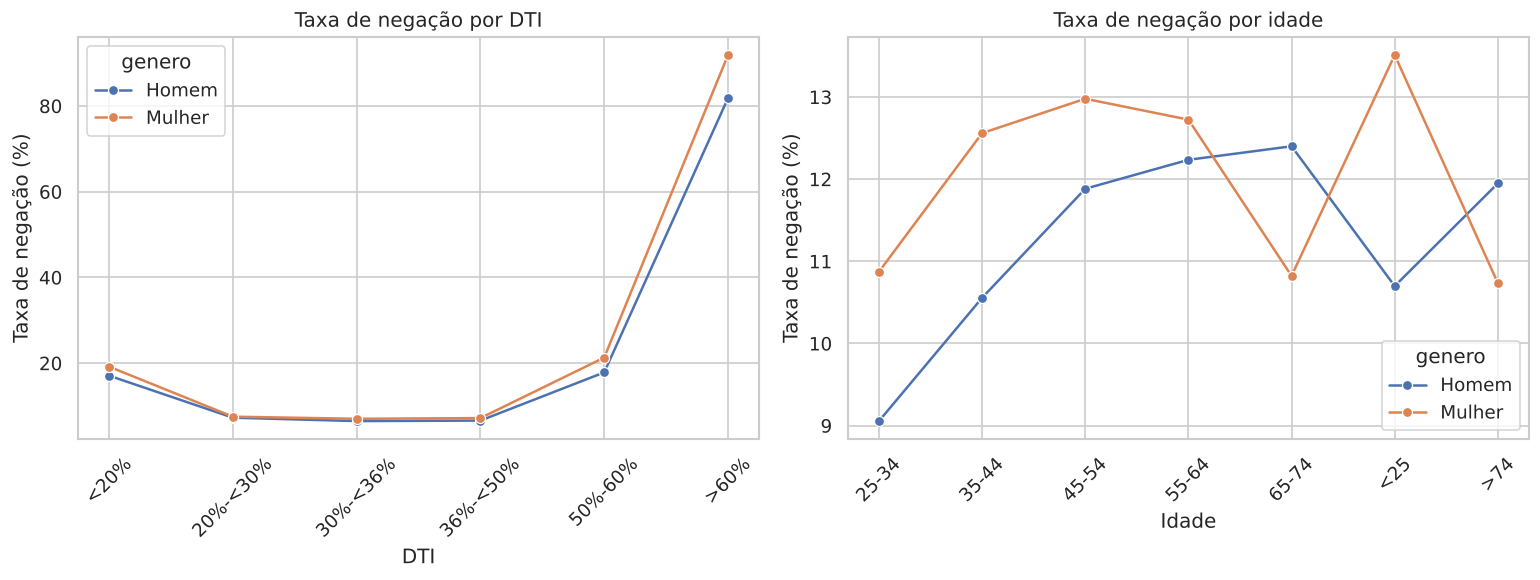

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

tabelas_grafico = {
    "dti": "Taxa de negação por DTI",
    "applicant_age": "Taxa de negação por idade"
}

for ax, (coluna, titulo) in zip(axes, tabelas_grafico.items()):
    tabela = estratos.groupby([coluna, "genero"], observed=True)["negado"].mean().reset_index()
    tabela["negado"] *= 100
    sns.lineplot(data=tabela, x=coluna, y="negado", hue="genero", marker="o", ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("DTI" if coluna == "dti" else "Idade")
    ax.set_ylabel("Taxa de negação (%)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../figuras/taxa_negacao_por_estratos.png")
plt.show()

## 6. Faltantes

A amostra principal usa apenas casos completos de renda, DTI e LTV (protocolo, seção 4). Confirmamos abaixo que não há faltantes nessas variáveis. A comparação com imputação pertence à análise de robustez, com a `amostra_alternativa`.

In [ ]:
chaves = ["income", "dti", "combined_loan_to_value_ratio"]

faltantes_chaves = data.groupby("genero")[chaves].apply(lambda g: g.isna().sum())
display(faltantes_chaves)

assert data[chaves].notna().all().all(), "A amostra principal deveria ter apenas casos completos."

,income,dti,combined_loan_to_value_ratio
genero,,,
Homem,0,0,0
Mulher,0,0,0
